# Part 4: Task of Delivery Operations Dataset

In [2]:
import os
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["LOKY_MAX_CPU_COUNT"] = "4"

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans, DBSCAN

In [4]:
df = pd.read_csv("delivery_operations_students.csv", encoding="utf-8-sig")
df

,order_id,distance_km,delivery_time_min,preparation_time_min,order_value_egp
0,DLV-0001,2.2,14,22,206
1,DLV-0002,2.1,17,12,190
2,DLV-0003,2.2,12,8,119
3,DLV-0004,2.0,22,11,113
4,DLV-0005,9.8,50,22,292
...,...,...,...,...,...
228,DLV-0229,6.5,23,15,193
229,DLV-0230,9.8,55,14,299
230,DLV-0231,1.9,12,21,135
231,DLV-0232,9.1,50,19,292


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 233 entries, 0 to 232
Data columns (total 5 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   order_id              233 non-null    object 
 1   distance_km           233 non-null    float64
 2   delivery_time_min     233 non-null    int64  
 3   preparation_time_min  233 non-null    int64  
 4   order_value_egp       233 non-null    int64  
dtypes: float64(1), int64(3), object(1)
memory usage: 9.2+ KB


In [6]:
df.describe()

,distance_km,delivery_time_min,preparation_time_min,order_value_egp
count,233.000000,233.000000,233.000000,233.000000
mean,5.731330,31.386266,16.012876,217.296137
std,3.546563,16.767841,3.491962,68.198764
min,0.500000,8.000000,8.000000,61.000000
25%,2.200000,17.000000,14.000000,166.000000
50%,5.300000,29.000000,16.000000,208.000000
75%,8.900000,44.000000,19.000000,264.000000
max,20.100000,110.000000,27.000000,510.000000


## 0) Visualizations

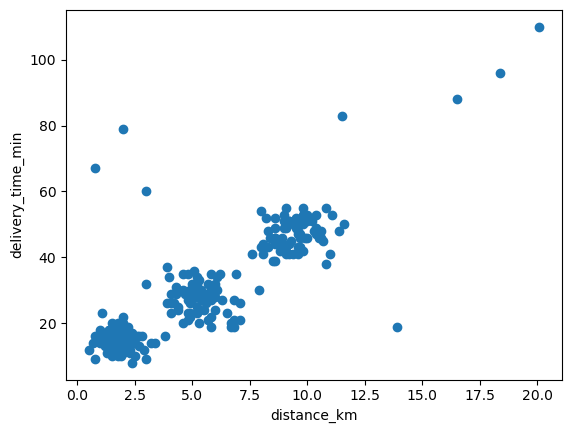

In [8]:
plt.scatter(df["distance_km"], df["delivery_time_min"])
plt.xlabel("distance_km")
plt.ylabel("delivery_time_min")
plt.show()

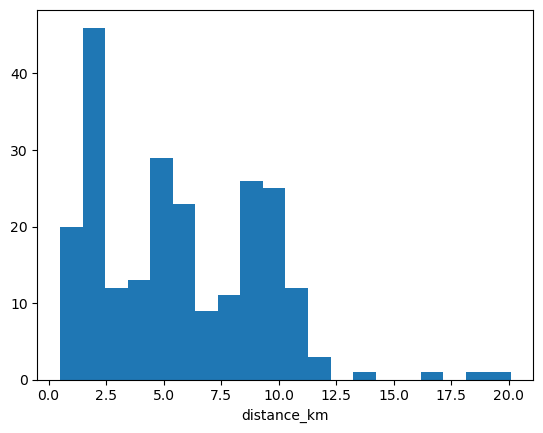

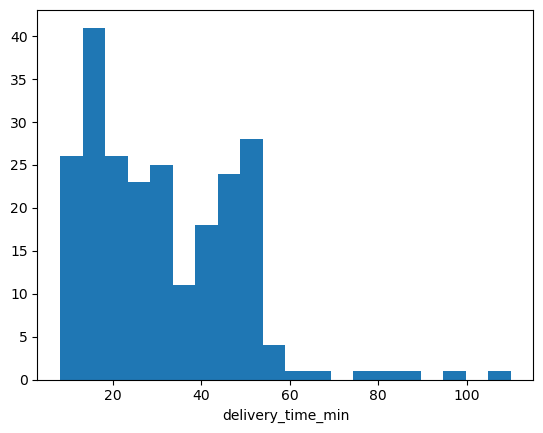

In [9]:
plt.hist(df["distance_km"], bins=20)
plt.xlabel("distance_km")
plt.show()

plt.hist(df["delivery_time_min"], bins=20)
plt.xlabel("delivery_time_min")
plt.show()

## 1) KMeans

In [11]:
X = df[['distance_km','delivery_time_min']]
X

,distance_km,delivery_time_min
0,2.2,14
1,2.1,17
2,2.2,12
3,2.0,22
4,9.8,50
...,...,...
228,6.5,23
229,9.8,55
230,1.9,12
231,9.1,50


In [12]:
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10, max_iter=300)
kmeans.fit(X)

KMeans(n_clusters=4, n_init=10, random_state=42)

In [13]:
df["kmeans_cluster"] = kmeans.labels_
df

,order_id,distance_km,delivery_time_min,preparation_time_min,order_value_egp,kmeans_cluster
0,DLV-0001,2.2,14,22,206,0
1,DLV-0002,2.1,17,12,190,0
2,DLV-0003,2.2,12,8,119,0
3,DLV-0004,2.0,22,11,113,0
4,DLV-0005,9.8,50,22,292,1
...,...,...,...,...,...,...
228,DLV-0229,6.5,23,15,193,2
229,DLV-0230,9.8,55,14,299,1
230,DLV-0231,1.9,12,21,135,0
231,DLV-0232,9.1,50,19,292,1


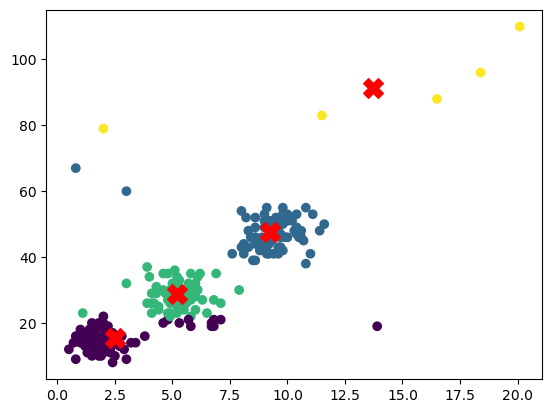

In [14]:
plt.scatter(df["distance_km"], df["delivery_time_min"], c=df["kmeans_cluster"])
plt.scatter(kmeans.cluster_centers_[:,0], kmeans.cluster_centers_[:,1], s=200, marker="X", c="red")
plt.show()

In [15]:
df["kmeans_cluster"].value_counts()

kmeans_cluster
0    85
1    77
2    66
3     5
Name: count, dtype: int64

In [16]:
df.groupby("kmeans_cluster").agg(
    Orders_count = ("kmeans_cluster","count"),
    avg_distance = ("distance_km","mean"),
    avg_delivery_time = ("delivery_time_min","mean"),
    avg_prep_time = ("preparation_time_min","mean"),
    avg_order_value = ("order_value_egp","mean"),
)

,Orders_count,avg_distance,avg_delivery_time,avg_prep_time,avg_order_value
kmeans_cluster,,,,,
0,85,2.518824,15.282353,14.129412,162.941176
1,77,9.223377,47.623377,17.207792,278.922078
2,66,5.190909,28.651515,16.818182,206.863636
3,5,13.700000,91.200000,19.000000,330.000000


**Explain Results**

- Cluster 0: 85 أوردر، مسافة قريبة (حوالي 2.5 كم) ووقت توصيل قليل (حوالي 15 دقيقة) وقيمة الأوردر أقل حاجة.
- Cluster 2: 66 أوردر، مسافة ووقت متوسطين (حوالي 5 كم و 29 دقيقة).
- Cluster 1: 77 أوردر، مسافة بعيدة (حوالي 9 كم) ووقت أطول (حوالي 48 دقيقة) وقيمة الأوردر أعلى.
- Cluster 3: 5 أوردرات بس، مسافة كبيرة جداً ووقت توصيل طويل جداً (حوالي 91 دقيقة)، وده أبطأ نوع أوردرات.

يعني كل ما المسافة بتزيد وقت التوصيل وقيمة الأوردر بيزيدوا.

## 2) Elbow and Inertia

In [19]:
inertias = []
for k in range(1,9):
  model = KMeans(n_clusters=k, random_state=42, n_init=10, max_iter=300)
  model.fit(X)
  inertias.append(model.inertia_)
inertias

[68147.3573390558,
 21122.763124800247,
 11635.329919295675,
 5268.248649859938,
 3972.116898944192,
 2914.7338821882504,
 2246.8141183555913,
 1913.9473638262314]

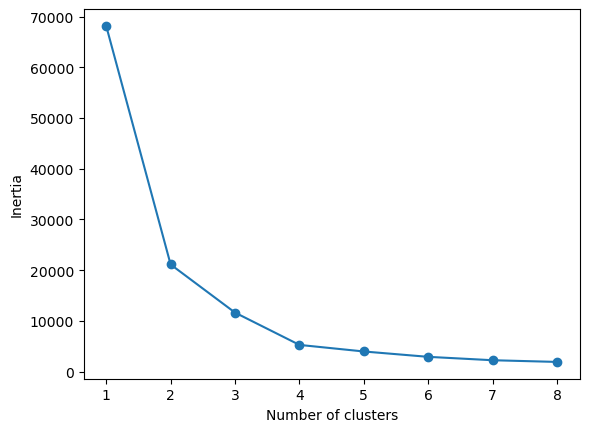

In [20]:
plt.plot(range(1,9), inertias, marker="o")
plt.xlabel("Number of clusters")
plt.ylabel("Inertia")
plt.show()

الـ inertia بتقل بسرعة من K=1 لحد K=4، وبعد K=4 النزول بيبقى بطيء، يعني الكوع (Elbow) عند K=4 وده سبب اختيار 4 clusters.

## 3) DBSCAN

In [23]:
dbscan = DBSCAN(eps=2, min_samples=5)
dbscan.fit(X)
df["DBSCAN_Clusters"] = dbscan.labels_
df

,order_id,distance_km,delivery_time_min,preparation_time_min,order_value_egp,kmeans_cluster,DBSCAN_Clusters
0,DLV-0001,2.2,14,22,206,0,0
1,DLV-0002,2.1,17,12,190,0,0
2,DLV-0003,2.2,12,8,119,0,0
3,DLV-0004,2.0,22,11,113,0,0
4,DLV-0005,9.8,50,22,292,1,1
...,...,...,...,...,...,...,...
228,DLV-0229,6.5,23,15,193,2,2
229,DLV-0230,9.8,55,14,299,1,1
230,DLV-0231,1.9,12,21,135,0,0
231,DLV-0232,9.1,50,19,292,1,1


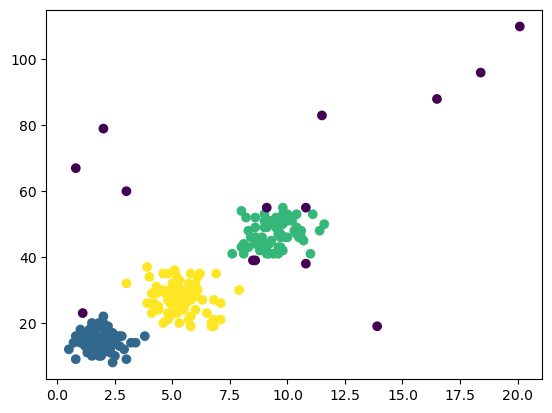

In [24]:
plt.scatter(df["distance_km"], df["delivery_time_min"], c=df["DBSCAN_Clusters"])
plt.show()

In [25]:
point_types = ["Border"] * len(X)
for i in dbscan.core_sample_indices_:
  point_types[i] = "Core"
for i,label in enumerate(dbscan.labels_):
  if label == -1:
    point_types[i] = "Noise"
df["point_type"] = point_types
df

,order_id,distance_km,delivery_time_min,preparation_time_min,order_value_egp,kmeans_cluster,DBSCAN_Clusters,point_type
0,DLV-0001,2.2,14,22,206,0,0,Core
1,DLV-0002,2.1,17,12,190,0,0,Core
2,DLV-0003,2.2,12,8,119,0,0,Core
3,DLV-0004,2.0,22,11,113,0,0,Border
4,DLV-0005,9.8,50,22,292,1,1,Core
...,...,...,...,...,...,...,...,...
228,DLV-0229,6.5,23,15,193,2,2,Core
229,DLV-0230,9.8,55,14,299,1,1,Border
230,DLV-0231,1.9,12,21,135,0,0,Core
231,DLV-0232,9.1,50,19,292,1,1,Core


In [26]:
df["point_type"].value_counts()

point_type
Core      212
Noise      14
Border      7
Name: count, dtype: int64

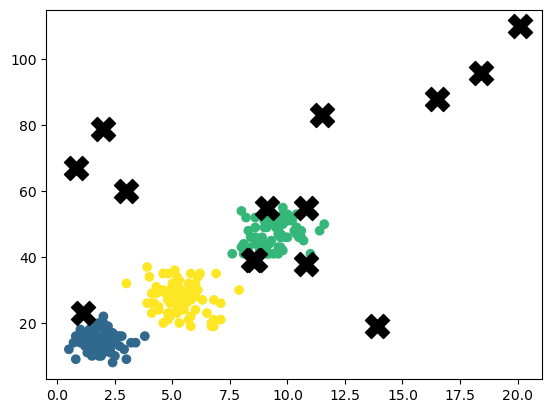

In [27]:
noise_point = (df["DBSCAN_Clusters"] == -1)
plt.scatter(df["distance_km"], df["delivery_time_min"], c=df["DBSCAN_Clusters"])
plt.scatter(df[noise_point]['distance_km'], df[noise_point]['delivery_time_min'], marker="X", color='black', s=300)
plt.show()

In [28]:
df.groupby("DBSCAN_Clusters").agg(
    Orders_count = ("DBSCAN_Clusters","count"),
    avg_distance = ("distance_km","mean"),
    avg_delivery_time = ("delivery_time_min","mean"),
)

,Orders_count,avg_distance,avg_delivery_time
DBSCAN_Clusters,,,
-1,14,9.650000,60.785714
0,74,1.890541,14.581081
1,70,9.408571,47.342857
2,75,5.357333,27.586667


## 4) Effect of Hyper-Parameters (eps, min_samples)

In [30]:
for eps in [1, 1.5, 2, 3, 5]:
  m = DBSCAN(eps=eps, min_samples=5)
  m.fit(X)
  print("eps =", eps, "| clusters =", len(set(m.labels_)) - (1 if -1 in m.labels_ else 0), "| noise =", list(m.labels_).count(-1), "| core =", len(m.core_sample_indices_))

eps = 1 | clusters = 10 | noise = 86 | core = 99
eps = 1.5 | clusters = 3 | noise = 21 | core = 199
eps = 2 | clusters = 3 | noise = 14 | core = 212
eps = 3 | clusters = 2 | noise = 8 | core = 223
eps = 5 | clusters = 1 | noise = 8 | core = 225


In [31]:
for ms in [3, 5, 8, 12, 20]:
  m = DBSCAN(eps=2, min_samples=ms)
  m.fit(X)
  print("min_samples =", ms, "| clusters =", len(set(m.labels_)) - (1 if -1 in m.labels_ else 0), "| noise =", list(m.labels_).count(-1), "| core =", len(m.core_sample_indices_))

min_samples = 3 | clusters = 3 | noise = 11 | core = 220
min_samples = 5 | clusters = 3 | noise = 14 | core = 212
min_samples = 8 | clusters = 3 | noise = 17 | core = 195
min_samples = 12 | clusters = 3 | noise = 41 | core = 152
min_samples = 20 | clusters = 2 | noise = 150 | core = 48


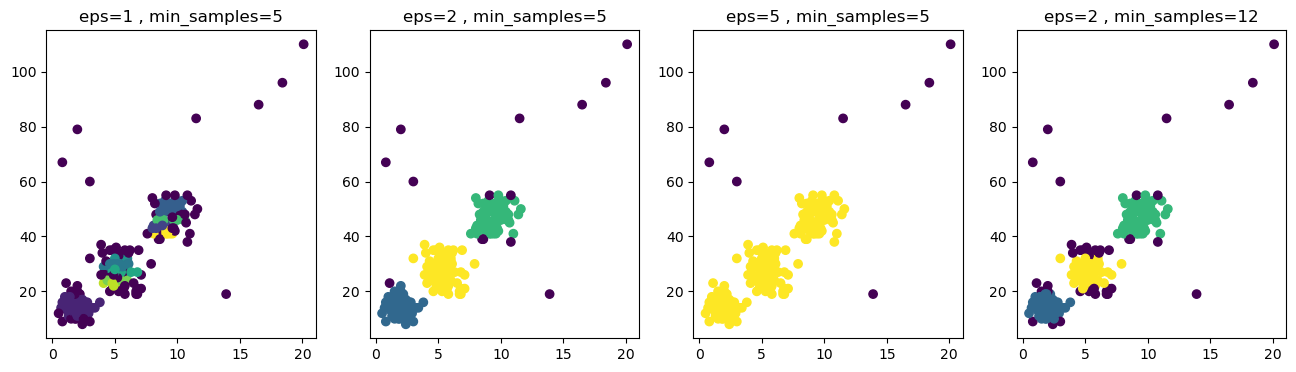

In [32]:
plt.figure(figsize=(16,4))
for i,(eps,ms) in enumerate([(1,5),(2,5),(5,5),(2,12)]):
  m = DBSCAN(eps=eps, min_samples=ms)
  m.fit(X)
  plt.subplot(1,4,i+1)
  plt.scatter(df["distance_km"], df["delivery_time_min"], c=m.labels_)
  plt.title("eps=" + str(eps) + " , min_samples=" + str(ms))
plt.show()

**eps**
- لما eps بيبقى صغير (1) النقط مش بتوصل لبعض، فبيطلع clusters كتير (10) و noise كتير (86).
- لما eps بيكبر (5) كل النقط بتتجمع في cluster واحد.
- eps = 2 كان مناسب: 3 clusters و 14 noise.

**min_samples**
- لما min_samples بيزيد، عدد الـ core بيقل والـ noise بيزيد (من 11 لحد 150 عند 20).
- min_samples = 5 كان مناسب مع eps = 2.

## 5) Final comparison (KMeans, DBSCAN)

In [35]:
pd.crosstab(df["kmeans_cluster"], df["DBSCAN_Clusters"])

DBSCAN_Clusters,-1,0,1,2
kmeans_cluster,,,,
0,1,74,0,10
1,7,0,70,0
2,1,0,0,65
3,5,0,0,0


| | KMeans | DBSCAN |
|---|---|---|
| عدد الـ clusters | بنحدده احنا (K=4) | بيطلع لوحده (3 clusters) |
| الـ Outliers | بيدخلهم جوه clusters | بيعتبرهم Noise (14 أوردر) |
| الحساسية | لاختيار K | لاختيار eps و min_samples |

- KMeans قسم الأوردرات لـ 4 أنواع (قريب، متوسط، بعيد، وأوردرات بطيئة جداً).
- DBSCAN طلع 3 مجموعات بنفس تقسيم (قريب، متوسط، بعيد) تقريباً، وفصل الأوردرات الغريبة كـ Noise، زي الأوردرات اللي مسافتها قليلة ووقتها طويل.
- KMeans أحسن لتقسيم الأوردرات لفئات، و DBSCAN أحسن لاكتشاف الأوردرات الشاذة اللي محتاجة مراجعة.